# 02 · Time-Series Analysis

**Goal:** learn how daily revenue behaves (level, trend, weekly and yearly seasonality, volatility, memory) so that the features and models in notebooks 03-04 are chosen for good reasons.

> **Scope guard.** Everything here uses the **pool only** (2009-12-01 to 2011-11-08). The final 30-day test set (2011-11-09 to 2011-12-08) is never looked at in this notebook, so nothing learned here can be tuned to it.

Every chart is followed by what it shows and what it means for forecasting.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # works from the project root or from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from src import config, plotting
from src import data_preprocessing as dp, evaluate as ev, feature_engineering as fe
plotting.apply_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
GBP = FuncFormatter(plotting.gbp)
print("project folder:", ROOT.name)

project folder: retail-sales-forecasting


In [2]:
daily = dp.load_daily_metrics()
series = dp.to_revenue_series(daily)
pool, test = ev.chronological_split(series)          # test is NOT used below
pool_daily = daily[daily["date"] <= pool.index[-1]].copy()
pool_daily["dow"] = pool_daily["date"].dt.dayofweek
trading = pool_daily[pool_daily["is_trading_day"] == 1]

print(f"Pool: {pool.index[0].date()} -> {pool.index[-1].date()} | {len(pool)} calendar days, {len(trading)} trading days")
print(f"Mean revenue per calendar day: GBP {pool.mean():,.0f} | per trading day: GBP {trading['revenue'].mean():,.0f} "
      f"| median trading day: GBP {trading['revenue'].median():,.0f}")

Pool: 2009-12-01 -> 2011-11-08 | 708 calendar days, 577 trading days
Mean revenue per calendar day: GBP 25,205 | per trading day: GBP 30,927 | median trading day: GBP 27,346


## 1 · The big picture: level, trend and the rolling averages

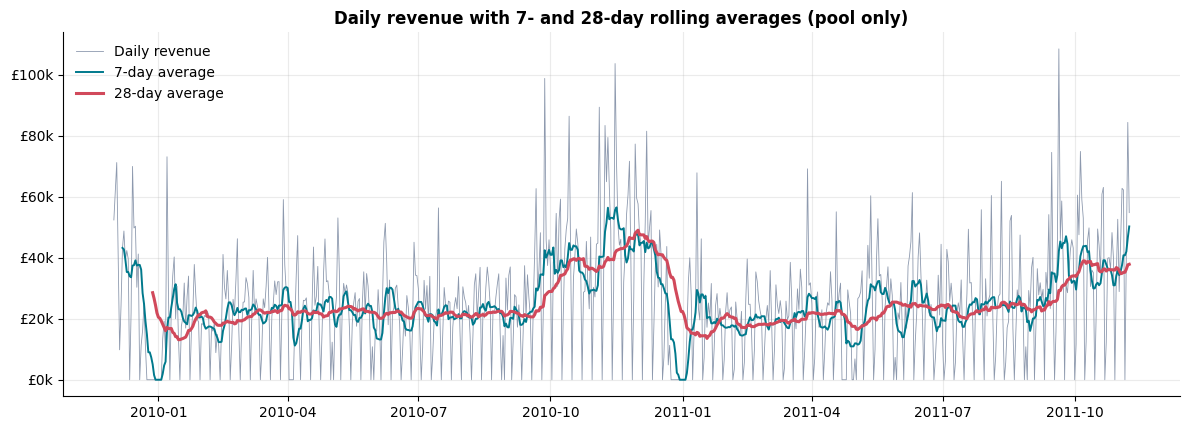

28-day average: lowest GBP 13,122 on 2010-01-15 | highest GBP 49,003 on 2010-12-01


In [3]:
roll7 = pool.rolling(7).mean()
roll28 = pool.rolling(28).mean()

fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(pool.index, pool.values, lw=0.6, color=plotting.COLORS["muted"], label="Daily revenue")
ax.plot(roll7.index, roll7.values, lw=1.4, color=plotting.COLORS["accent"], label="7-day average")
ax.plot(roll28.index, roll28.values, lw=2.2, color=plotting.COLORS["forecast"], label="28-day average")
ax.yaxis.set_major_formatter(GBP)
ax.set_title("Daily revenue with 7- and 28-day rolling averages (pool only)")
ax.legend(loc="upper left")
fig.tight_layout()
plotting.save_figure(fig, "fig06_daily_revenue_rolling.png")
plt.show()

print(f"28-day average: lowest GBP {roll28.min():,.0f} on {roll28.idxmin().date()} | highest GBP {roll28.max():,.0f} on {roll28.idxmax().date()}")

**What it shows.** Daily revenue is noisy, but the 28-day average reveals a clear yearly rhythm: a quiet first half of the year, a climb from September, a peak in the autumn and a collapse over the end-of-year shutdown. The zero days (Saturdays, holidays, the year-end closure) pull the 7-day average down repeatedly.

**For forecasting.** A model needs (a) calendar information to know *when* the business is closed and (b) recent-level information (rolling means) to know *how busy* the current season is.

## 2 · Weekly and monthly revenue

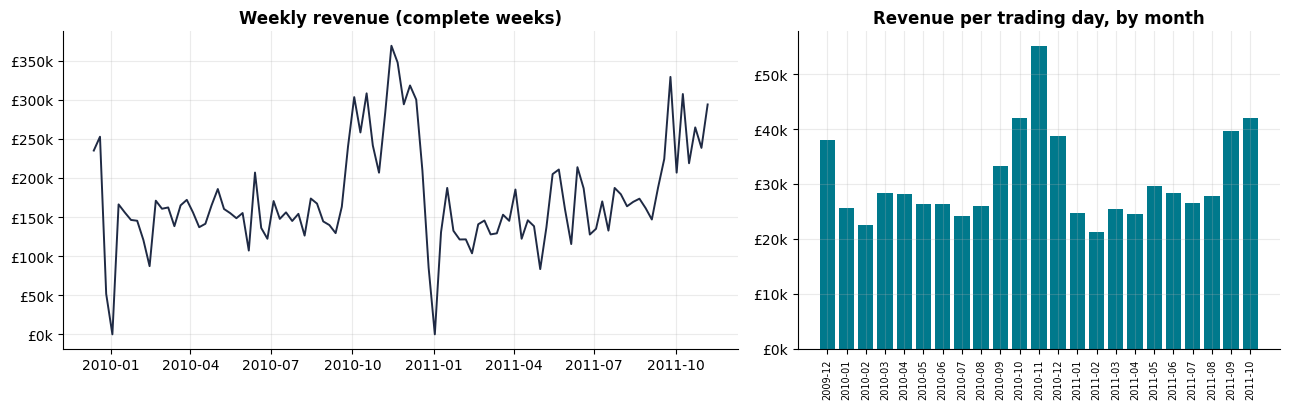

,revenue,trading_days,revenue_per_trading_day
date,,,
2009-12,"798,658.00",21,"38,031.00"
2010-01,"613,589.00",24,"25,566.00"
2010-02,"539,335.00",24,"22,472.00"
2010-03,"763,258.00",27,"28,269.00"
2010-04,"647,146.00",23,"28,137.00"
2010-05,"631,267.00",24,"26,303.00"
2010-06,"685,787.00",26,"26,376.00"
2010-07,"629,236.00",26,"24,201.00"
2010-08,"675,318.00",26,"25,974.00"


In [4]:
weekly = pool.resample("W-SUN").sum()
weekly = weekly.iloc[1:-1]                      # drop the partial first and last weeks
month_key = pool_daily["date"].dt.to_period("M")
monthly = pool_daily.groupby(month_key).agg(revenue=("revenue", "sum"), trading_days=("is_trading_day", "sum"))
monthly["revenue_per_trading_day"] = monthly["revenue"] / monthly["trading_days"]
complete = monthly.iloc[:-1]                    # the last month (Nov 2011) is only 8 days in the pool

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].plot(weekly.index, weekly.values, color=plotting.COLORS["actual"], lw=1.4)
axes[0].yaxis.set_major_formatter(GBP)
axes[0].set_title("Weekly revenue (complete weeks)")
axes[1].bar(complete.index.astype(str), complete["revenue_per_trading_day"], color=plotting.COLORS["accent"])
axes[1].yaxis.set_major_formatter(GBP)
axes[1].set_title("Revenue per trading day, by month")
axes[1].tick_params(axis="x", rotation=90, labelsize=7)
fig.tight_layout()
plotting.save_figure(fig, "fig07_weekly_monthly_revenue.png")
plt.show()
complete.assign(revenue=lambda d: d["revenue"].round(0), revenue_per_trading_day=lambda d: d["revenue_per_trading_day"].round(0))

**What it shows.** Revenue per trading day is lowest in January and February, flat through the summer, then rises sharply from September to a November peak in 2010, before falling back in December as the shop heads into its year-end closure. Looking at *revenue per trading day* (not monthly totals) separates real demand from the number of days the business was open.

**Caution.** November 2011 is excluded from this chart because only its first 8 days belong to the pool.

## 3 · Weekday pattern

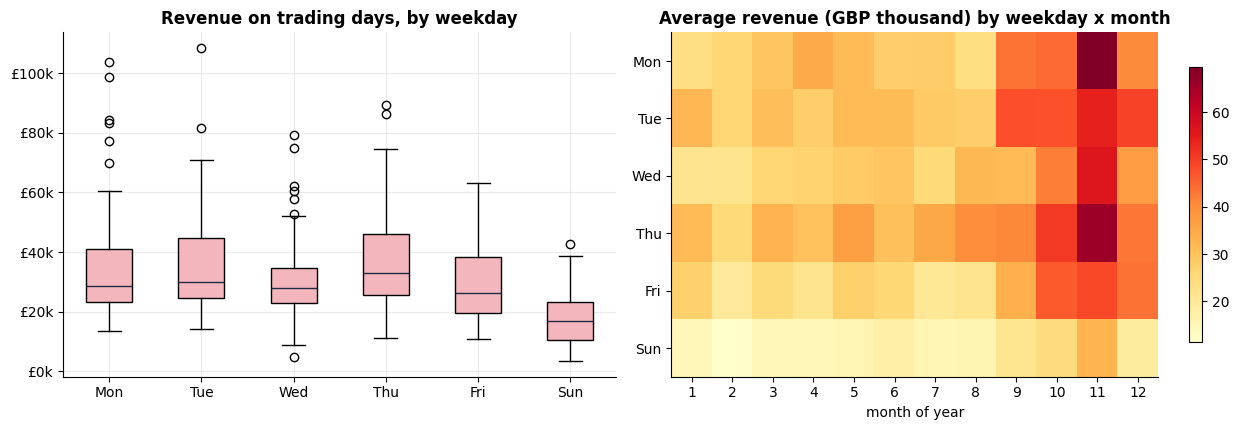

     count      mean    median
Mon     90 34,466.00 28,761.00
Tue    100 35,567.00 29,889.00
Wed     99 30,785.00 28,069.00
Thu     98 37,584.00 32,895.00
Fri     94 29,361.00 26,231.00
Sat      1  9,803.00  9,803.00
Sun     95 17,747.00 16,958.00

Saturdays with any sales in the pool: 1 of 101


In [5]:
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
groups = [trading.loc[trading["dow"] == k, "revenue"].values for k in [0, 1, 2, 3, 4, 6]]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
axes[0].boxplot(groups, tick_labels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sun"], patch_artist=True,
                boxprops={"facecolor": plotting.COLORS["interval"]}, medianprops={"color": plotting.COLORS["actual"]})
axes[0].yaxis.set_major_formatter(GBP)
axes[0].set_title("Revenue on trading days, by weekday")

pool_month = pool_daily.assign(month=pool_daily["date"].dt.month)
heat = (pool_month[pool_month["is_trading_day"] == 1].pivot_table(index="dow", columns="month", values="revenue", aggfunc="mean")
        .reindex(index=[0, 1, 2, 3, 4, 6]))
im = axes[1].imshow(heat.values / 1000, aspect="auto", cmap="YlOrRd")
axes[1].set_xticks(range(len(heat.columns)), labels=heat.columns)
axes[1].set_yticks(range(len(heat.index)), labels=[names[i] for i in heat.index])
axes[1].set_title("Average revenue (GBP thousand) by weekday x month")
axes[1].set_xlabel("month of year")
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], shrink=0.8)
fig.tight_layout()
plotting.save_figure(fig, "fig08_weekday_pattern.png")
plt.show()

summary = trading.groupby("dow")["revenue"].agg(["count", "mean", "median"])
summary.index = [names[i] for i in summary.index]
print(summary.round(0).to_string())
print("\nSaturdays with any sales in the pool:", int(((pool_daily["dow"] == 5) & (pool_daily["is_trading_day"] == 1)).sum()),
      "of", int((pool_daily["dow"] == 5).sum()))

**What it shows.** Weekdays are the busy days (Thursday and Tuesday on average the strongest, Friday weaker), **Sunday is roughly half a weekday**, and **Saturday is effectively closed** (one trading Saturday in the whole pool). In the heatmap November is the strongest month for every trading weekday, with September, October and December usually next.

**For forecasting.** `day_of_week` is an essential feature. Month matters too, but the heatmap mixes only one to two years per cell, so month effects should be learned cautiously (a model must not memorise individual calendar days).

## 4 · Year-over-year seasonality and growth

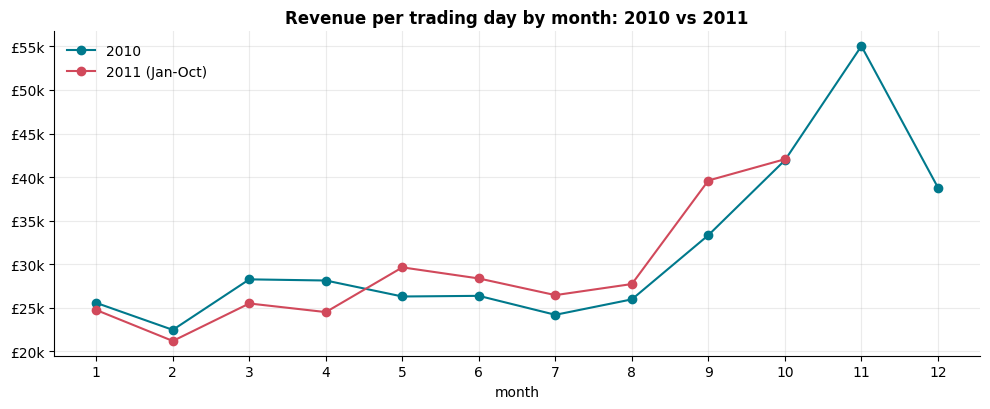

Revenue growth Jan-Oct 2011 vs Jan-Oct 2010: +2.5%
Revenue growth Sep-Oct 2011 vs Sep-Oct 2010: +8.5%


In [6]:
by_year = pool_daily.assign(year=pool_daily["date"].dt.year, month=pool_daily["date"].dt.month)
per_td = (by_year.groupby(["year", "month"]).agg(rev=("revenue", "sum"), td=("is_trading_day", "sum"))
          .assign(per_td=lambda d: d["rev"] / d["td"])["per_td"].unstack(0))
per_td_2011 = per_td[2011].copy()
per_td_2011.loc[11] = np.nan                       # Nov 2011 is incomplete in the pool

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(per_td.index, per_td[2010], marker="o", color=plotting.COLORS["accent"], label="2010")
ax.plot(per_td.index, per_td_2011, marker="o", color=plotting.COLORS["forecast"], label="2011 (Jan-Oct)")
ax.yaxis.set_major_formatter(GBP)
ax.set_xticks(range(1, 13))
ax.set_xlabel("month")
ax.set_title("Revenue per trading day by month: 2010 vs 2011")
ax.legend()
fig.tight_layout()
plotting.save_figure(fig, "fig09_monthly_seasonality_yoy.png")
plt.show()

def total(year, months):
    sel = by_year[(by_year["year"] == year) & (by_year["month"].isin(months))]
    return sel["revenue"].sum()

jan_oct = total(2011, range(1, 11)) / total(2010, range(1, 11)) - 1
sep_oct = total(2011, [9, 10]) / total(2010, [9, 10]) - 1
print(f"Revenue growth Jan-Oct 2011 vs Jan-Oct 2010: {jan_oct * 100:+.1f}%")
print(f"Revenue growth Sep-Oct 2011 vs Sep-Oct 2010: {sep_oct * 100:+.1f}%")

**What it shows.** The 2011 curve follows the same shape as 2010: low early in the year, a September-October ramp. Overall growth between the two years is modest and uneven across months. Comparing like-for-like months (January to October) removes the incomplete-year problem.

**Caution.** With only two Decembers and a single complete autumn peak (2010) in the pool, a model cannot reliably learn the Christmas-season shape from data alone. That is a real limitation, documented in the README.

## 5 · Volatility

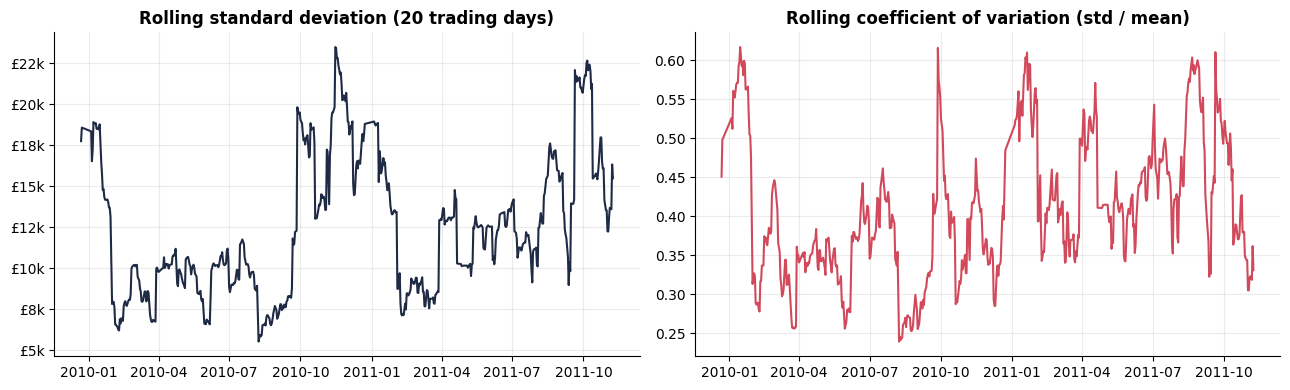

Overall coefficient of variation on trading days: 0.51
Rolling CV: median 0.40, min 0.24, max 0.62


In [7]:
td_series = trading.set_index("date")["revenue"]
roll_std = td_series.rolling(20).std()
roll_cv = roll_std / td_series.rolling(20).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(roll_std.index, roll_std.values, color=plotting.COLORS["actual"])
axes[0].yaxis.set_major_formatter(GBP)
axes[0].set_title("Rolling standard deviation (20 trading days)")
axes[1].plot(roll_cv.index, roll_cv.values, color=plotting.COLORS["forecast"])
axes[1].set_title("Rolling coefficient of variation (std / mean)")
fig.tight_layout()
plotting.save_figure(fig, "fig10_volatility.png")
plt.show()
print(f"Overall coefficient of variation on trading days: {td_series.std() / td_series.mean():.2f}")
print(f"Rolling CV: median {roll_cv.median():.2f}, min {roll_cv.min():.2f}, max {roll_cv.max():.2f}")

**What it shows.** The *absolute* day-to-day spread rises and falls with the level of revenue (its rolling standard deviation peaks in the November 2010 rush), while the *relative* spread (coefficient of variation) is much steadier from month to month, typically between about 0.35 and 0.42 and higher in January when trading restarts after the closure. Across the whole pool a typical trading day deviates from the average by about half of the average.

**For forecasting.** Day-level revenue is intrinsically hard to predict precisely; even a good model will miss individual days by a large amount in absolute pounds. That is why we measure success against baselines, report errors in pounds *and* percent, and provide an empirical prediction interval.

## 6 · Memory: autocorrelation

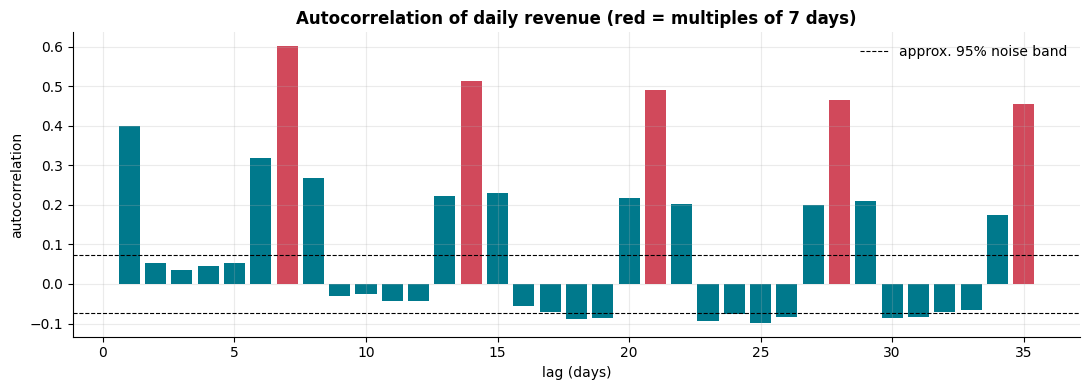

Strongest autocorrelations (lag: value): {7: 0.601, 14: 0.512, 21: 0.491, 28: 0.464, 35: 0.454, 1: 0.4}
Selected lags: {1: 0.4, 7: 0.601, 14: 0.512, 28: 0.464}


In [8]:
x = pool.values - pool.values.mean()
denominator = np.sum(x * x)
max_lag = 35
acf = np.array([np.sum(x[k:] * x[:len(x) - k]) / denominator for k in range(max_lag + 1)])
bound = 1.96 / np.sqrt(len(x))

fig, ax = plt.subplots(figsize=(11, 4))
lags = np.arange(1, max_lag + 1)
colors = [plotting.COLORS["forecast"] if l % 7 == 0 else plotting.COLORS["accent"] for l in lags]
ax.bar(lags, acf[1:], color=colors)
ax.axhline(bound, color="black", ls="--", lw=0.8)
ax.axhline(-bound, color="black", ls="--", lw=0.8, label="approx. 95% noise band")
ax.set_xlabel("lag (days)")
ax.set_ylabel("autocorrelation")
ax.set_title("Autocorrelation of daily revenue (red = multiples of 7 days)")
ax.legend()
fig.tight_layout()
plotting.save_figure(fig, "fig11_autocorrelation.png")
plt.show()

top = sorted(range(1, max_lag + 1), key=lambda k: acf[k], reverse=True)[:6]
print("Strongest autocorrelations (lag: value):", {k: round(float(acf[k]), 3) for k in top})
print("Selected lags:", {k: round(float(acf[k]), 3) for k in config.LAG_PERIODS})

**What it shows.** Yesterday's revenue is only moderately informative (lag 1), whereas the **same weekday one week earlier (lag 7) is the strongest memory**, followed by the other multiples of 7 (14, 21, 28, 35 days). Revenue repeats weekly because the business has a weekly rhythm.

**For forecasting.** This is the evidence behind the lag set `1, 7, 14, 28` and the rolling means over `7, 14, 28` days: lags at multiples of seven capture the weekday rhythm, rolling means capture the current seasonal level.

## 7 · Distribution and outliers

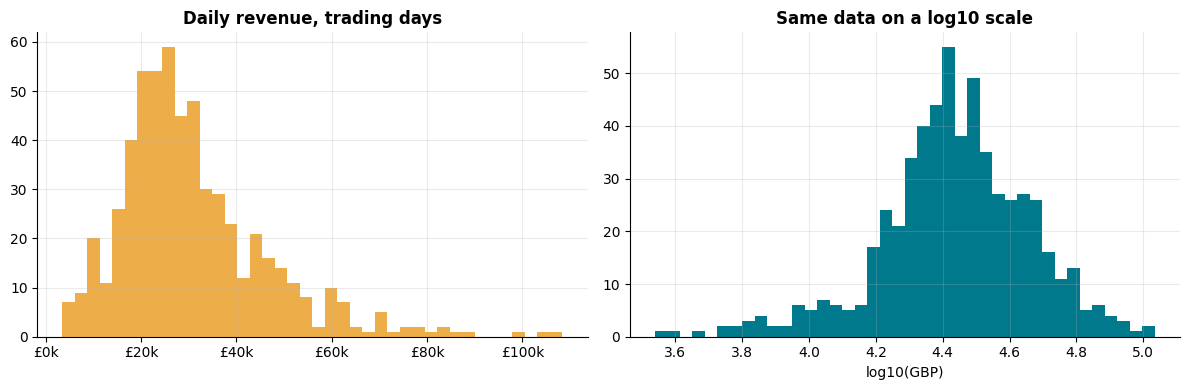

Skewness: 1.37 | IQR fence for 'unusually high' days: GBP 62,784
Days above the fence: 23 of 577


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(trading["revenue"], bins=40, color=plotting.COLORS["highlight"])
axes[0].xaxis.set_major_formatter(GBP)
axes[0].set_title("Daily revenue, trading days")
axes[1].hist(np.log10(trading["revenue"]), bins=40, color=plotting.COLORS["accent"])
axes[1].set_title("Same data on a log10 scale")
axes[1].set_xlabel("log10(GBP)")
fig.tight_layout()
plotting.save_figure(fig, "fig12_revenue_distribution_pool.png")
plt.show()

q1, q3 = trading["revenue"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print(f"Skewness: {trading['revenue'].skew():.2f} | IQR fence for 'unusually high' days: GBP {upper_fence:,.0f}")
print(f"Days above the fence: {(trading['revenue'] > upper_fence).sum()} of {len(trading)}")

**What it shows.** Trading-day revenue is right-skewed (a few very strong days). A log transform reduces the skewness (from about 1.4 to about -0.5, now slightly left-skewed). We still keep the **raw GBP target** so that errors stay in the business unit, and rely on tree models and robust metrics rather than transforming the target.

## 8 · Major peaks and drops

In [10]:
cols = ["date", "revenue", "n_invoices", "n_customers"]
top = trading.nlargest(8, "revenue")[cols].assign(weekday=lambda d: d["date"].dt.day_name())
low = trading.nsmallest(8, "revenue")[cols].assign(weekday=lambda d: d["date"].dt.day_name())
print("Highest-revenue days in the pool:"); print(top.to_string(index=False))
print("\nLowest non-zero days in the pool:"); print(low.to_string(index=False))

Highest-revenue days in the pool:
      date    revenue  n_invoices  n_customers  weekday
2011-09-20 108,422.47          70           53  Tuesday
2010-11-15 103,610.93         102           83   Monday
2010-09-27  98,739.33          85           65   Monday
2010-11-04  89,310.81         131          103 Thursday
2010-10-14  86,356.53          97           81 Thursday
2011-11-07  84,326.52          92           80   Monday
2010-11-08  83,331.04          80           66   Monday
2010-12-07  81,443.74          82           65  Tuesday

Lowest non-zero days in the pool:
      date  revenue  n_invoices  n_customers   weekday
2011-02-06 3,457.11          11           11    Sunday
2011-03-13 4,100.04          16           16    Sunday
2010-12-22 4,856.57          16           13 Wednesday
2011-02-13 5,636.88          19           19    Sunday
2011-08-14 5,708.62          25           21    Sunday
2011-07-10 5,834.57          24           20    Sunday
2011-07-03 6,032.39          25           

**What it shows.** Seven of the eight strongest days fall between September and November, the run-up to Christmas (the eighth is 7 December 2010). Seven of the eight weakest trading days are Sundays; the other is 22 December 2010, two days before the year-end closure.

These are **observed historical patterns**. We do not claim to know *why* a particular day was strong (promotions, large wholesale buyers, weather); correlation in this data does not establish causes.

## 9 · What this means for modeling (decisions)

| Finding (pool only) | Modeling decision |
|---|---|
| Strong weekday rhythm; Saturday closed | `day_of_week`, `is_weekend` calendar features |
| Holidays and 24 Dec - 3 Jan have zero revenue | `is_uk_holiday`, `is_year_end_closure` features, plus a zero-forecast rule for these known closures |
| Weekly memory (lag 7 strongest) | Lags 1, 7, 14, 28 |
| Slowly moving seasonal level | Rolling means over 7, 14, 28 days (past only) |
| Right-skewed, volatile days | Report MAE (primary), RMSE, WAPE, sMAPE; use baselines for context |
| Only ~2 years of history | Keep models simple; expect limited ability to learn the Christmas peak |